# Reproducing Tonneau et al. 2025 (Phys. Med. Biol. 70 235021)

R. Tonneau *et al.*, *Decoding the chemistry of the FLASH effect: a physicochemical model of dose-rate, pH and oxygen-dependent H$_2$O$_2$ production*, Phys. Med. Biol. **70** (2025) 235021, doi:[10.1088/1361-6560/ae1fcc](https://doi.org/10.1088/1361-6560/ae1fcc). This is the foundational paper of radiopyo (PDF in `docs/literature/`).

This notebook redraws its main results with the current radiopyo:

| Paper | Here |
|---|---|
| Fig. 4: O$_2$ versus time | 2×2 panels: CDR / UHDR × 1 % / 5 % pO$_2$ |
| Fig. 5: $\Delta$[O$_2$] map at 500 s | dose rate × initial pO$_2$, in %pO$_2$ and µM |
| Fig. 6: gross O$_2$ production / consumption | bars, with the net depletion |
| Fig. 7: H$_2$O$_2$ versus time | 2×2 panels |
| Fig. 8: net H$_2$O$_2$ yield map | #/100 eV, slope over 10/20/30 Gy |
| Fig. 9: gross H$_2$O$_2$ production / consumption | bars, with the net production |
| Fig. 10: pH versus time | 2×2 panels |

plus a table comparing the values quoted in the paper's text with radiopyo.

**Two scenarios** (`paper_runs.SCENARIOS`, switch `SCENARIO` below):

- `"methods"` (default): what the paper's methods describe (table 3), the bundled pure-water config at LET 1.17 keV/µm;
- `"original"`: the inputs of the original runs whose results are quoted in the paper's text, the author's config `data/CONFIG_PAPER_01.toml` (four rate constants differ from the bundled config) at LET 0.56 keV/µm. With the current code it reproduces those runs to about 0.03 % and the quoted values to about 1 % (see the last sections).

**Data.** All runs live in `paper_runs.py` (next to this notebook). The same module writes the golden files `tests/golden/data/paper_tonneau_2025.npz` (paper methods, `tests/golden/record_golden.py --only paper`) and `paper_tonneau_2025_original.npz` (original inputs, `--only paper-original`), which `tests/golden/test_paper_tonneau_2025.py` checks. By default the notebook loads the file of `SCENARIO`. Set `RECOMPUTE = True` to re-run the whole grid (1083 runs, about 10 min with 8 workers) and print the gap to the golden file.

## Scenario

Paper tables 3 and 5, as run by `paper_runs.py`:

- `"methods"`: bundled pure-water config (`radiopyo.PURE_WATER_CONFIG_FILE`) and LET 1.17 keV/µm; `"original"`: `data/CONFIG_PAPER_01.toml` and LET 0.56 keV/µm. Everything below is common to both;
- 25 °C, pH 7 ([H$_3$O$^+$] = [OH$^-$] = 10$^{-7}$ M), [H$_2$O] = 55.5 M;
- Boscolo 2020 G-values at the LET of the scenario, scaled by GF(DR) (`variable_GValues` on);
- one single pulse from t = 0, 30 Gy for the figures (10 and 20 Gy as well for the net-yield fit), integrated over (0, 500 s) with LSODA (atol 10$^{-12}$ µM, rtol 10$^{-10}$, first step 10$^{-15}$ s: the radiopyo defaults, same as the paper);
- maximum step: pulse width / 500 with the beam ON, 0.1 s after it;
- initial [O$_2$] = pO$_2$ [%] / 100 × 1300 µM (Henry); the first 10$^{-7}$ s are added analytically (initial burst), so time series start at 10$^{-7}$ s;
- CDR / UHDR threshold: 100 Gy/s; hypoxia 1 %, physioxia 5 % pO$_2$.

**GF(DR) gap (ADR 0009).** Fig. 3B of the paper prints GF(DR) = 0.982·DR$^{-0.09}$, while radiopyo ships 0.972·DR$^{-0.1097}$ (a later fit on the whole Blain data set). The original runs quoted in the text used the shipped fit (it can be read back from their stored G-values), so this notebook runs the shipped fit in both scenarios; the printed fit belongs to a later rerun at LET 1.17 (see the last section). The table below shows the two fits: the shipped one is 4 % higher at 0.1 Gy/s, equal near 1 Gy/s and 28 % lower at 10$^7$ Gy/s.

In [1]:
import importlib.util
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib import colors
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

# "methods" (paper methods: bundled config, LET 1.17 keV/µm) or "original"
# (inputs of the runs quoted in the text: CONFIG_PAPER_01.toml, LET 0.56)
SCENARIO = "methods"
# True: re-run the whole grid with paper_runs.py instead of loading the
# golden file, and report the gap to it (about 10 min with 8 workers)
RECOMPUTE = False
WORKERS = 8

HERE = Path.cwd().resolve()
ROOT = next(
    p for p in (HERE, *HERE.parents)
    if (p / "pyproject.toml").exists() and (p / "radiopyo").is_dir()
)
if importlib.util.find_spec("radiopyo") is None:  # not installed: repo copy
    sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / "examples" / "tonneau_2025_pmb"))

import paper_runs as pr

from radiopyo.utils.g_values import GValuesBoscolo

GOLDEN_DIR = ROOT / "tests" / "golden" / "data"
GOLDEN_FILES = {
    "methods": GOLDEN_DIR / "paper_tonneau_2025.npz",
    "original": GOLDEN_DIR / "paper_tonneau_2025_original.npz",
}
GOLDEN_FILE = GOLDEN_FILES[SCENARIO]
print(f"scenario {SCENARIO!r}: {pr.SCENARIOS[SCENARIO].description}")
UHDR_LIMIT = 100.0  # Gy/s

scenario 'methods': paper methods: bundled pure-water config, LET 1.17 keV/µm


In [2]:
golden = pr.load_grid(GOLDEN_FILE)
if RECOMPUTE:
    def progress(done: int, total: int) -> None:
        if done % 100 == 0 or done == total:
            print(f"{done}/{total} runs", flush=True)

    grid = pr.run_grid(workers=WORKERS, progress=progress, scenario=SCENARIO)
    gaps = {}
    for key in pr.GRID_KEYS:
        new, ref = np.asarray(grid[key], float), np.asarray(golden[key], float)
        gaps[key] = (
            float(np.max(np.abs(new - ref) / np.maximum(np.abs(ref), 1e-12)))
            if new.shape == ref.shape else np.nan
        )
    display(pd.Series(gaps, name="max relative difference to the golden file").to_frame())
else:
    grid = golden

DR = grid["dose_rates"]        # map dose rates [Gy/s]
PO2 = grid["po2"]              # map initial pO2 [%]
DOSES = grid["doses"]          # [Gy], the last one is the 30 Gy of the figures
TS_DR = grid["ts_dose_rates"]  # paper table 5
TIME = grid["time"]            # [s]


def ij(dose_rate: float, po2: float) -> tuple[int, int]:
    return pr.index_of(DR, dose_rate), pr.index_of(PO2, po2)


def fmt_dr(dose_rate: float) -> str:
    exp = int(np.floor(np.log10(dose_rate) + 1e-9))
    if -1 <= exp <= 1:
        return f"{dose_rate:g}"
    mant = dose_rate / 10.0**exp
    return ("" if np.isclose(mant, 1.0) else f"{mant:g}×") + f"10$^{{{exp}}}$"


print(f"{DR.size} dose rates × {PO2.size} pO2 × {DOSES.size} doses")

19 dose rates × 19 pO2 × 3 doses


In [3]:
pd.DataFrame(
    {
        "regime": ["CDR" if d < UHDR_LIMIT else "UHDR" for d in TS_DR],
        "pulse width [s] (30 Gy)": DOSES[-1] / TS_DR,
        "GF radiopyo": [GValuesBoscolo._scale_factor(d) for d in TS_DR],
        "GF paper (fig. 3B)": 0.982 * TS_DR**-0.09,
    },
    index=pd.Index(TS_DR, name="dose rate [Gy/s]"),
).style.format_index("{:g}").format({"pulse width [s] (30 Gy)": "{:.3g}", "GF radiopyo": "{:.3f}", "GF paper (fig. 3B)": "{:.3f}"})

,regime,pulse width [s] (30 Gy),GF radiopyo,GF paper (fig. 3B)
dose rate [Gy/s],,,,
0.1,CDR,300,1.251,1.208
1,CDR,30,0.972,0.982
10,CDR,3,0.755,0.798
50,CDR,0.6,0.633,0.691
100,UHDR,0.3,0.586,0.649
1000,UHDR,0.03,0.456,0.527
10000,UHDR,0.003,0.354,0.429
100000,UHDR,0.0003,0.275,0.348
1e+06,UHDR,3e-05,0.213,0.283


## Time evolution (figs. 4, 7 and 10)

30 Gy in one pulse; colour = dose rate (paper table 5), darker = lower within each regime.

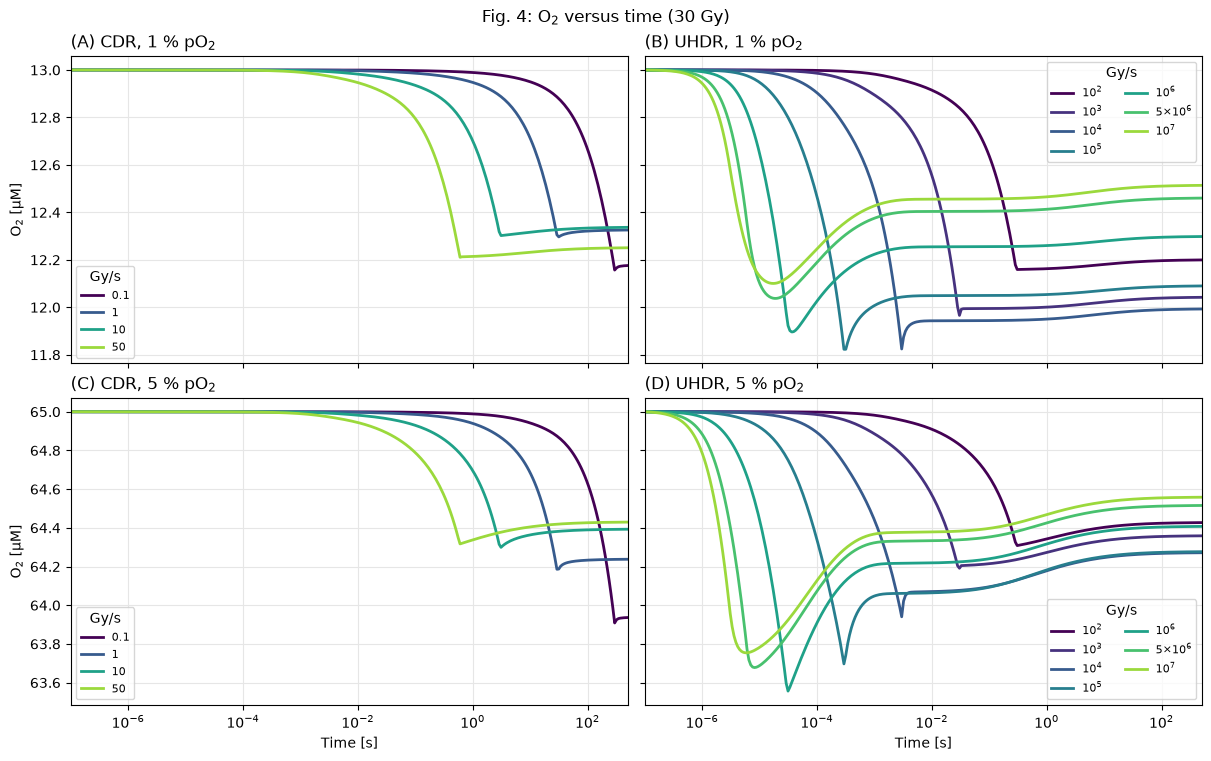

In [4]:
DR_CMAP = plt.get_cmap("viridis")


def plot_time_series(key: str, ylabel: str, title: str, ylim=None) -> None:
    fig, axes = plt.subplots(
        2, 2, figsize=(12, 7.5), sharex=True, sharey="row", constrained_layout=True
    )
    regimes = (("CDR", TS_DR < UHDR_LIMIT), ("UHDR", TS_DR >= UHDR_LIMIT))
    for b, po2 in enumerate(grid["ts_po2"]):
        for c, (regime, sel) in enumerate(regimes):
            ax = axes[b, c]
            idx = np.flatnonzero(sel)
            shades = DR_CMAP(np.linspace(0.0, 0.85, idx.size))  # by rank, no pale yellow
            for a, shade in zip(idx, shades):
                ax.plot(TIME, grid[key][a, b], color=shade, lw=2, label=fmt_dr(TS_DR[a]))
            ax.set_xscale("log")
            ax.set_xlim(TIME[0], TIME[-1])
            if ylim is not None:
                ax.set_ylim(*ylim)
            ax.grid(color="0.9")
            ax.set_title(f"({'ABCD'[2 * b + c]}) {regime}, {po2:g} % pO$_2$", loc="left")
            if c == 0:
                ax.set_ylabel(ylabel)
            if b == 1:
                ax.set_xlabel("Time [s]")
            ax.legend(title="Gy/s", fontsize=8, ncol=1 if c == 0 else 2, loc="best")
    fig.suptitle(title)
    plt.show()


plot_time_series("ts_o2", "O$_2$ [µM]", "Fig. 4: O$_2$ versus time (30 Gy)")

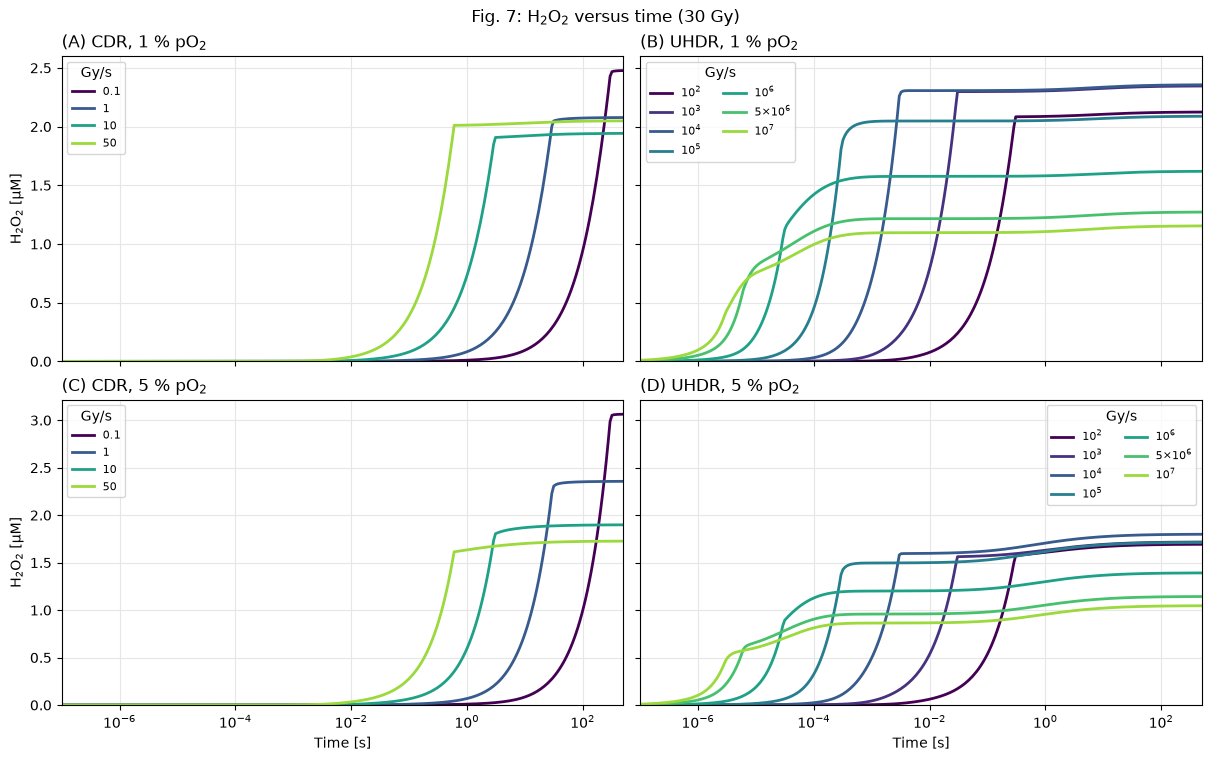

In [5]:
plot_time_series("ts_h2o2", "H$_2$O$_2$ [µM]", "Fig. 7: H$_2$O$_2$ versus time (30 Gy)", ylim=(0, None))

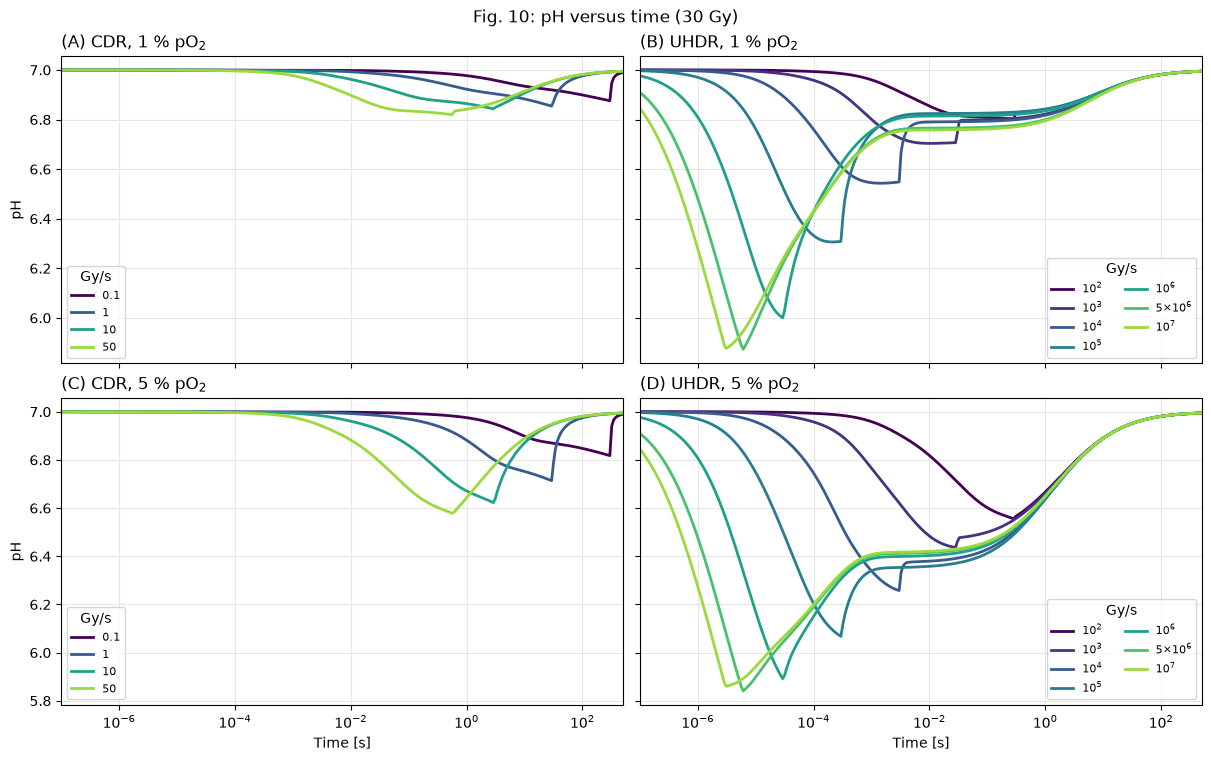

In [6]:
plot_time_series("ts_ph", "pH", "Fig. 10: pH versus time (30 Gy)")

## Maps (figs. 5 and 8)

Dose rate × initial pO$_2$, 30 Gy for $\Delta$[O$_2$]. The net H$_2$O$_2$ yield is the slope of a linear fit of [H$_2$O$_2$] at 500 s versus the dose (10, 20, 30 Gy), in #/100 eV (1 #/100 eV ≈ 0.1036 µM/Gy). Dashed line: CDR/UHDR threshold; dotted lines: physioxia range (4–7.5 % pO$_2$).

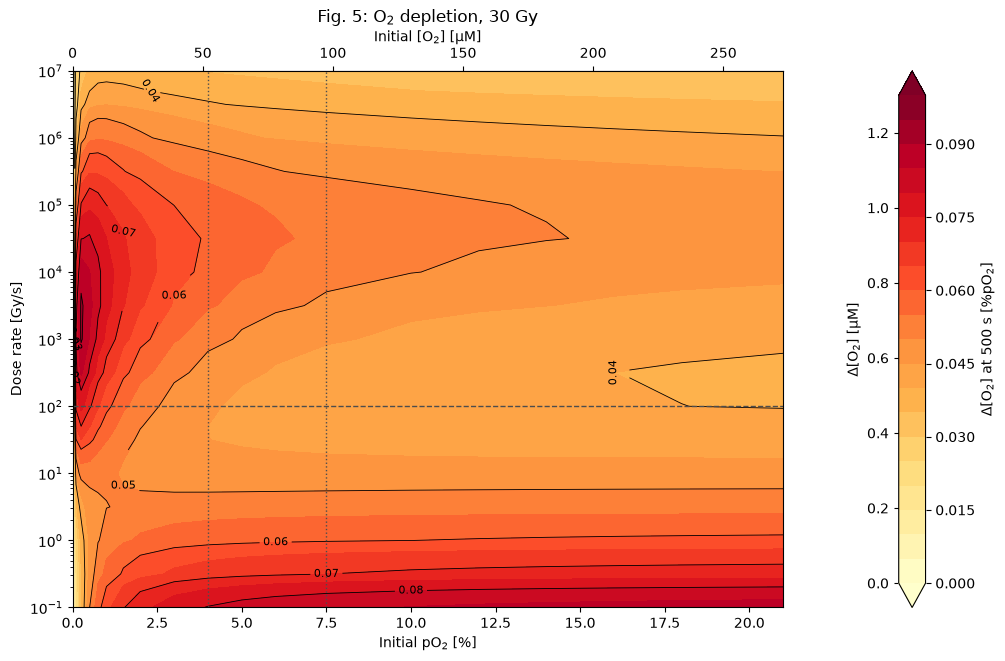

In [7]:
def plot_map(z, fill_levels, line_levels, cbar_label, title, cbar_second=None) -> None:
    fig, ax = plt.subplots(figsize=(10, 6.5), constrained_layout=True)
    X, Y = np.meshgrid(PO2, DR)
    cf = ax.contourf(X, Y, z, levels=fill_levels, cmap="YlOrRd", extend="both")
    cs = ax.contour(X, Y, z, levels=line_levels, colors="k", linewidths=0.6)
    ax.clabel(cs, fmt="%g", fontsize=8)
    ax.set_yscale("log")
    ax.set_xlabel("Initial pO$_2$ [%]")
    ax.set_ylabel("Dose rate [Gy/s]")
    top = ax.secondary_xaxis(
        "top", functions=(pr.o2_from_po2, lambda c: np.asarray(c) / pr.HENRY * 100.0)
    )
    top.set_xlabel("Initial [O$_2$] [µM]")
    ax.axhline(UHDR_LIMIT, ls="--", color="0.3", lw=1)
    for p in (4.0, 7.5):
        ax.axvline(p, ls=":", color="0.3", lw=1)
    cb = fig.colorbar(cf, ax=ax, pad=0.09 if cbar_second else 0.02)
    cb.set_label(cbar_label)
    if cbar_second is not None:
        label, forward, inverse = cbar_second
        sec = cb.ax.secondary_yaxis("left", functions=(forward, inverse))
        sec.set_ylabel(label)
    ax.set_title(title)
    plt.show()


delta_o2 = pr.delta_o2(grid)  # µM, (dose rate, pO2), 30 Gy
to_pct = 100.0 / pr.HENRY     # µM -> %pO2
plot_map(
    delta_o2 * to_pct,
    np.arange(0.0, 0.1001, 0.005),
    np.arange(0.01, 0.1001, 0.01),
    "$\\Delta$[O$_2$] at 500 s [%pO$_2$]",
    "Fig. 5: O$_2$ depletion, 30 Gy",
    cbar_second=("$\\Delta$[O$_2$] [µM]", lambda p: np.asarray(p) / to_pct, lambda c: np.asarray(c) * to_pct),
)

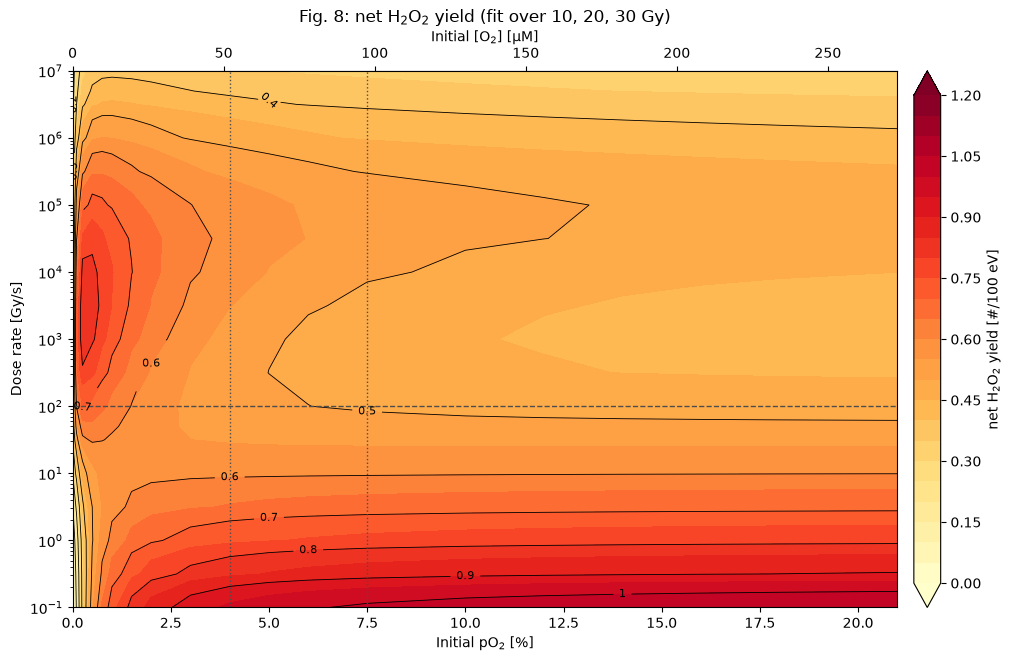

In [8]:
net_h2o2 = pr.net_yield_map(grid)  # #/100 eV, (dose rate, pO2)
plot_map(
    net_h2o2,
    np.arange(0.0, 1.2001, 0.05),
    np.arange(0.1, 1.2001, 0.1),
    "net H$_2$O$_2$ yield [#/100 eV]",
    "Fig. 8: net H$_2$O$_2$ yield (fit over 10, 20, 30 Gy)",
)

## Gross production and consumption (figs. 6 and 9)

Time integrals over (0, 500 s) of every rate producing (radiolytic yield included) or consuming the species, 30 Gy (`ODEResult.integrate_production_of` / `integrate_consumption_of`). Equilibria are counted once, as production or consumption according to their net integral. As in the paper, the light bar is the larger amount (O$_2$: consumption, H$_2$O$_2$: production), the dark bar the smaller one, and the black dash the net amount. The net is the integral balance: it also counts the initial burst, so it can differ slightly from the change in concentration.

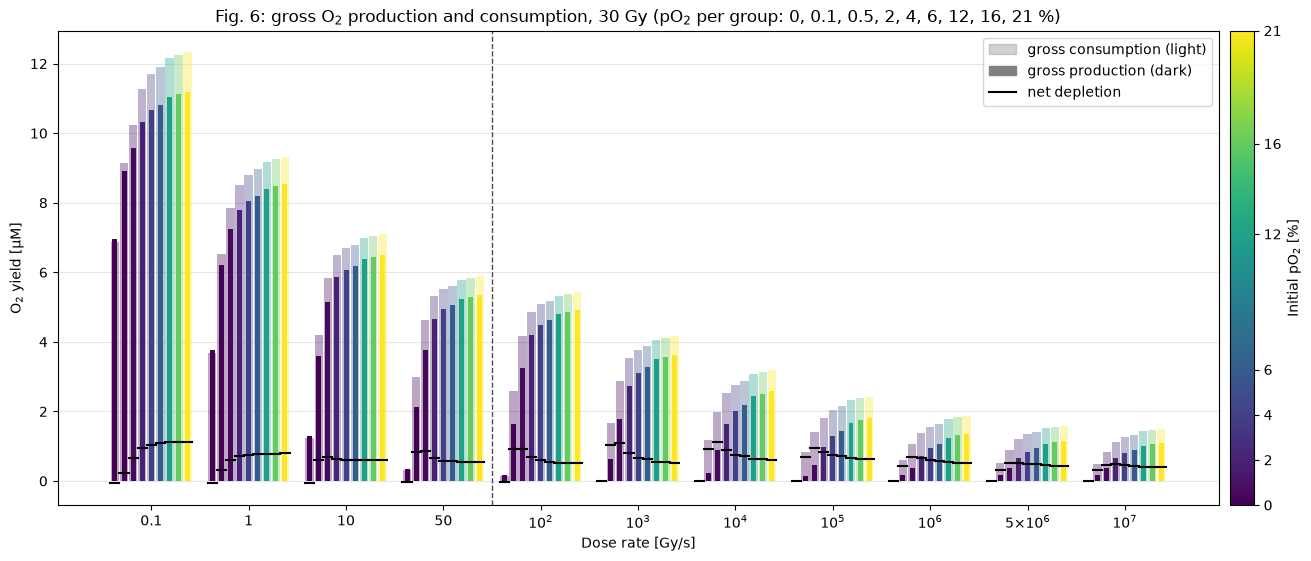

In [9]:
PO2_NORM = colors.Normalize(0.0, max(pr.BAR_PO2))
PO2_CMAP = plt.get_cmap("viridis")


def plot_bars(species: str, light: str, title: str) -> None:
    prod, cons = grid[f"{species}_production"], grid[f"{species}_consumption"]
    big, small = (cons, prod) if light == "consumption" else (prod, cons)
    sign = -1.0 if light == "consumption" else 1.0  # net = depletion or production
    n = len(pr.BAR_PO2)
    width = 0.84 / n
    fig, ax = plt.subplots(figsize=(13, 5.5), constrained_layout=True)
    for g, dr in enumerate(TS_DR):
        for k, po2 in enumerate(pr.BAR_PO2):
            i, j = ij(dr, po2)
            x = g + (k - (n - 1) / 2) * width
            col = PO2_CMAP(PO2_NORM(po2))
            ax.bar(x, big[i, j], width * 0.92, color=col, alpha=0.35, lw=0)
            ax.bar(x, small[i, j], width * 0.55, color=col, lw=0)
            net = sign * (prod[i, j] - cons[i, j])
            ax.plot([x - width / 2, x + width / 2], [net, net], color="k", lw=1.5)
    ax.set_xticks(range(len(TS_DR)), [fmt_dr(d) for d in TS_DR])
    ax.set_xlabel("Dose rate [Gy/s]")
    ax.set_ylabel(f"{'O$_2$' if species == 'o2' else 'H$_2$O$_2$'} yield [µM]")
    ax.axvline(np.searchsorted(TS_DR, UHDR_LIMIT) - 0.5, ls="--", color="0.3", lw=1)
    ax.grid(axis="y", color="0.9")
    ax.set_axisbelow(True)
    other = "production" if light == "consumption" else "consumption"
    ax.legend(
        handles=[
            Patch(color="0.5", alpha=0.35, label=f"gross {light} (light)"),
            Patch(color="0.5", label=f"gross {other} (dark)"),
            Line2D([], [], color="k", lw=1.5,
                   label="net depletion" if light == "consumption" else "net production"),
        ],
        loc="upper right",
    )
    cb = fig.colorbar(plt.cm.ScalarMappable(PO2_NORM, PO2_CMAP), ax=ax, pad=0.01)
    cb.set_label("Initial pO$_2$ [%]")
    cb.set_ticks([0, 2, 4, 6, 12, 16, 21])
    ax.set_title(title + f" (pO$_2$ per group: {', '.join(f'{p:g}' for p in pr.BAR_PO2)} %)")
    plt.show()


plot_bars("o2", "consumption", "Fig. 6: gross O$_2$ production and consumption, 30 Gy")

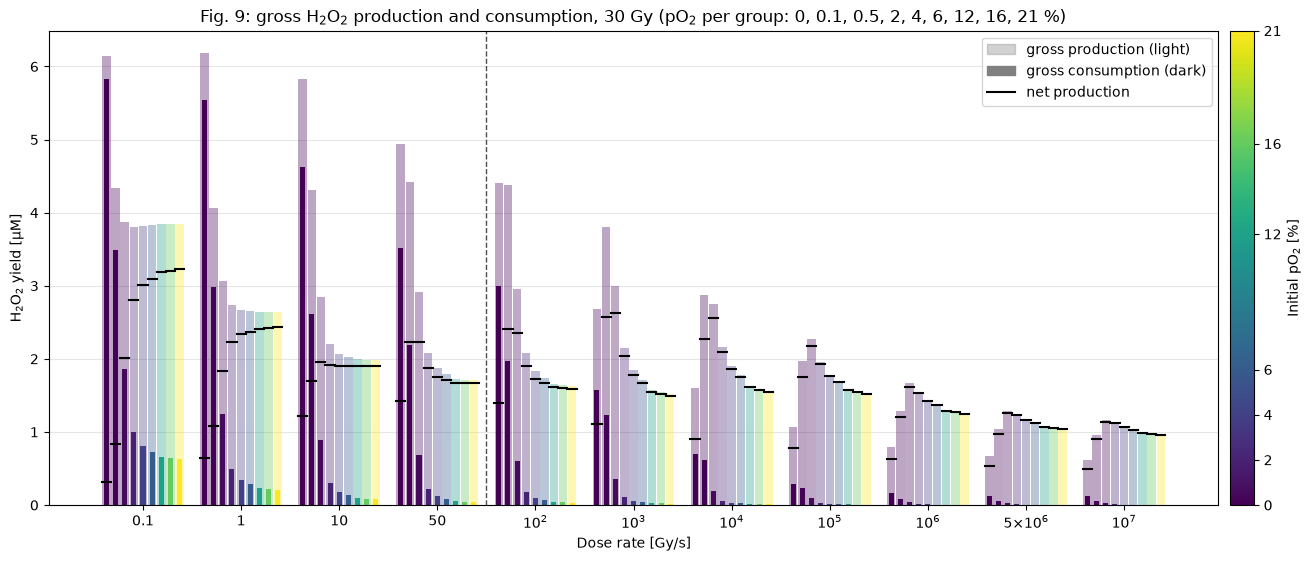

In [10]:
plot_bars("h2o2", "production", "Fig. 9: gross H$_2$O$_2$ production and consumption, 30 Gy")

## Values quoted in the paper versus radiopyo

Informational only (no assertion), both scenarios whatever `SCENARIO` is. "Paper" is the value quoted in the text; a range is split into its minimum and maximum over the CDR dose rates of table 5 (0.1–50 Gy/s).

In [11]:
grids = {name: pr.load_grid(path) for name, path in GOLDEN_FILES.items()}
grids[SCENARIO] = grid  # the recomputed grid when RECOMPUTE
quoted = {name: pr.quoted_values(g, UHDR_LIMIT) for name, g in grids.items()}
table = pd.DataFrame(
    [
        (q, cond, ref, m, orig[3], src)
        for (q, cond, ref, m, src), orig in zip(quoted["methods"], quoted["original"])
    ],
    columns=["quantity", "condition", "paper", "methods", "original", "source"],
)
for name in ("methods", "original"):
    table[f"{name} vs paper"] = table[name] / table["paper"] - 1.0
table.style.format(
    {"paper": "{:.3g}", "methods": "{:.3g}", "original": "{:.3g}",
     "methods vs paper": "{:+.0%}", "original vs paper": "{:+.0%}"}
).hide(axis="index")

quantity,condition,paper,methods,original,source,methods vs paper,original vs paper
final H2O2 [µM],"1 % pO2, 1e2 Gy/s",2.2,2.12,2.18,"§3.3, fig. 7B",-3%,-1%
final H2O2 [µM],"1 % pO2, 1e4 Gy/s",2.45,2.36,2.44,"§3.3, fig. 7B",-4%,-1%
final H2O2 [µM],"1 % pO2, 1e7 Gy/s",1.25,1.15,1.25,"§3.3, fig. 7B",-8%,-0%
final H2O2 [µM],"5 % pO2, 1e2 Gy/s",1.75,1.69,1.77,"§3.3 (1.7-1.8), fig. 7D",-3%,+1%
final H2O2 [µM],"5 % pO2, 1e7 Gy/s",1.1,1.05,1.1,"§3.3, fig. 7D",-5%,+0%
"final H2O2 [µM], CDR min",1 % pO2,2,1.94,2.05,§3.3 (2.0-2.7),-3%,+2%
"final H2O2 [µM], CDR max",1 % pO2,2.7,2.48,2.72,§3.3 (2.0-2.7),-8%,+1%
"final H2O2 [µM], CDR min",5 % pO2,1.7,1.73,1.82,§3.3 (1.7-3.3),+2%,+7%
"final H2O2 [µM], CDR max",5 % pO2,3.3,3.06,3.3,§3.3 (1.7-3.3),-7%,-0%
"ΔO2 at 500 s [µM], CDR min",1 and 5 % pO2,0.8,0.57,0.604,§3.2.1 (0.8-1.2),-29%,-24%


## Reading the gaps

- **The shapes are the paper's in both scenarios**: the O$_2$ dip and two-step recovery at UHDR, the H$_2$O$_2$ and $\Delta$[O$_2$] hot spots around 10$^3$–10$^4$ Gy/s at low pO$_2$ (< 1 %), the pH drop deepening with the dose rate, and the bell-shaped H$_2$O$_2$ gross production versus pO$_2$ at UHDR.
- **The paper's methods and its quoted values come from two different sets of runs.** The author's original results show it: the values quoted in the text come from runs at LET 0.56 keV/µm with the config `CONFIG_PAPER_01.toml` and the GF(DR) fit radiopyo ships (`sim_GVal_Dr_pH3.h5`, February 2025), while table 3 (LET 1.17 keV/µm) and the fit of fig. 3B (0.982·DR$^{-0.09}$) describe a later rerun (`sim_GVal_Dr_pH3_G21pO2.h5`, September 2025) whose results are up to 33 % above the quoted UHDR values. The figures of the published version may come from either.
- **`"original"` reproduces the quoted values**: final H$_2$O$_2$, gross O$_2$ yields, net H$_2$O$_2$ production and minimum pH within about 1 % (the CDR minimum of the final H$_2$O$_2$ at 5 % pO$_2$, +7 %, is the loose end of a quoted range), and the original runs themselves to about 0.03 %. The two $\Delta$[O$_2$] rows stay off in both scenarios (0.60 µM against the quoted 0.8 µM, 0.039 against ~0.03 µM/Gy) and in the original runs too: they are a reading of the figures, not a model gap.
- **`"methods"` is 3–8 % below** on most values. Against `"original"` it differs by the LET (G-values about 7 % lower at 1.17 than at 0.56 keV/µm) and by four rate constants of the config. Swapped one at a time: e$_{aq}$ + O$_2$ (2.29×10$^{10}$ against 1.9×10$^{10}$ M$^{-1}$s$^{-1}$ bundled) moves the CDR H$_2$O$_2$ by about 4 %, H$^•$ + O$_2$ (4.2×10$^{10}$ against 1.31×10$^{10}$) the UHDR one by about 2.5 %; H$^•$ + HO$_2$ and O$_2^-$ + O$^-$ do not matter here.
- The refactoring of radiopyo does not move these results (`pre_refactor_comparison.ipynb`), and the GF(DR) fit printed in the paper overshoots at UHDR with the bundled config (`gf_fit_comparison.ipynb`).
- The golden files pin what radiopyo produces now. A change to the model that moves these figures is a result-changing fix: re-record with `tests/golden/record_golden.py --force --only paper paper-original` once it is approved.